# natural thermalization: 10 qubits and 50 random circuits per depth

This notebook implements the updated circuit. The sweep loops over **1, 5, 10, 15, 20, 25, 30, 35, 40, 45, and 50 layers**. Each depth averages **50 random circuits**, with **1024 shots per circuit**. Every circuit starts in $|0\rangle^{\otimes 10}$.

One layer consists of these six rows in order:

1. fresh random RX rotations on all 10 qubits
2. RZZ gates on (0,1), (2,3), (4,5), (6,7), (8,9)
3. RZZ gates on (1,2), (3,4), (5,6), (7,8), with qubits 0 and 9 idle for this row
4. fresh random RY rotations on all 10 qubits
5. the same even-pair RZZ row as step 2
6. the same odd-pair RZZ row as step 3

The C_zz interactions use the existing RZZ(π/4) gates. RX and RY angles are independently drawn uniformly from −π/4 to +π/4 for every qubit, layer, and circuit. Each depth has its own reproducible random stream. This is not a Floquet circuit: successive layers have new rotation angles.

Only qubit 0 is measured, after the final layer. Each circuit's estimate is

$$\langle Z_0\rangle_j \approx \frac{N_{0,j}-N_{1,j}}{1024}.$$

`circuit_counts` stores the counts, `circuit_expectation_values` stores all 50 estimates per depth, and `results` stores their arithmetic mean:

$$\overline{\langle Z_0\rangle} = \frac{1}{50}\sum_{j=1}^{50}\langle Z_0\rangle_j.$$

The first circuit from the 1-layer and 5-layer experiments is displayed; each sample is included in its set of 50. The plot starts at **(0 layers, 1)**, the exact expectation value of the initial all-zero state. Finite averages can fluctuate around zero.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

n_qubits = 10
shots = 1024
n_random_circuits = 50
layer_values = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
seed = 2026
rotation_limit = np.pi / 4 #maximum rx and ry angle in radians
entangling_angle = np.pi / 4 #rzz interaction angle


plotting function below


In [2]:
#----- plotting: keep this section when replacing the data -----

def plot_expectation_values(depths, values, placeholder=True, output_path="thermalization_plot.png"):
    depths = np.asarray(depths, dtype=float)
    values = np.asarray(values, dtype=float)

    if depths.ndim != 1 or values.ndim != 1:
        raise ValueError("Depths and expectation values must be 1D arrays.")

    if len(depths) == 0 or len(depths) != len(values):
        raise ValueError("Provide the same nonzero number of depths and values.")

    if not np.all(np.isfinite(depths)) or not np.all(np.isfinite(values)):
        raise ValueError("All data must contain finite numbers.")

    if np.any(depths < 0):
        raise ValueError("Circuit depths cannot be negative.")

    if np.any((values < -1) | (values > 1)):
        raise ValueError("Pauli-Z expectation values must be between -1 and 1.")

    #arrange points in increasing circuit-depth order.
    order = np.argsort(depths)
    depths = depths[order]
    values = values[order]

    fig, ax = plt.subplots(figsize=(9, 5)) #creates a graph and a set of subplots with a specified size

    #--- this is all graph styling and labeling, not quantum-circuit code. ---
    #draws data points and connects them with lines
    ax.plot(
        depths,
        values,
        color="#0099AB",
        linewidth=2,
        marker="o",
        markersize=4,
        label="Synthetic placeholder data" if placeholder else "Mean of 50 random circuits",
    )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)

    ax.set_xlabel("Number of layers", fontsize=12)
    ax.set_ylabel(
        r"Mean Pauli-$Z$ expectation value $\langle Z_0\rangle$",
        fontsize=12,
    )
    ax.set_title(
        "Illustrative Relaxation — Placeholder Data"
        if placeholder
        else "Mean Pauli-Z Expectation Value vs. Number of Layers"
    )

    ax.set_xlim(left=0)
    ax.set_ylim(-1.05, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

## sweep over circuit layers

Run setup and the plotting-function cell first, then run this cell once to calculate every depth in `layer_values`. Each depth gets 50 new random circuits. Rerunning the sweep clears the previous results and restores the initial point (0, 1).


1 layer(s): mean <Z_0> = +0.792891 over 50 random circuits, 1024 shots each


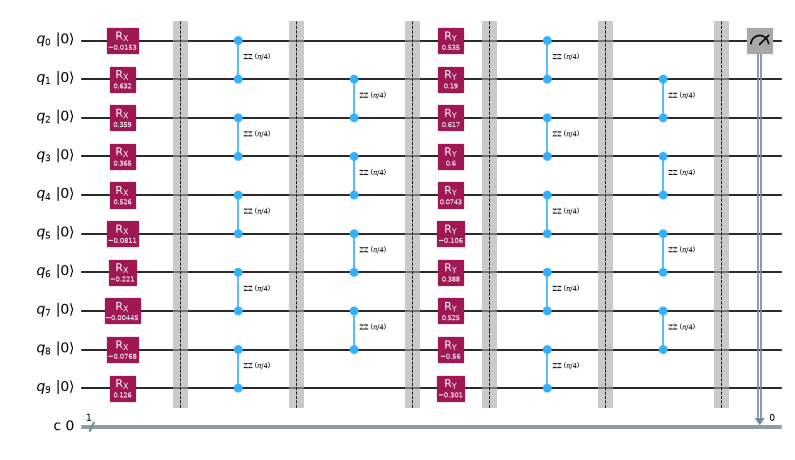

5 layer(s): mean <Z_0> = +0.348359 over 50 random circuits, 1024 shots each


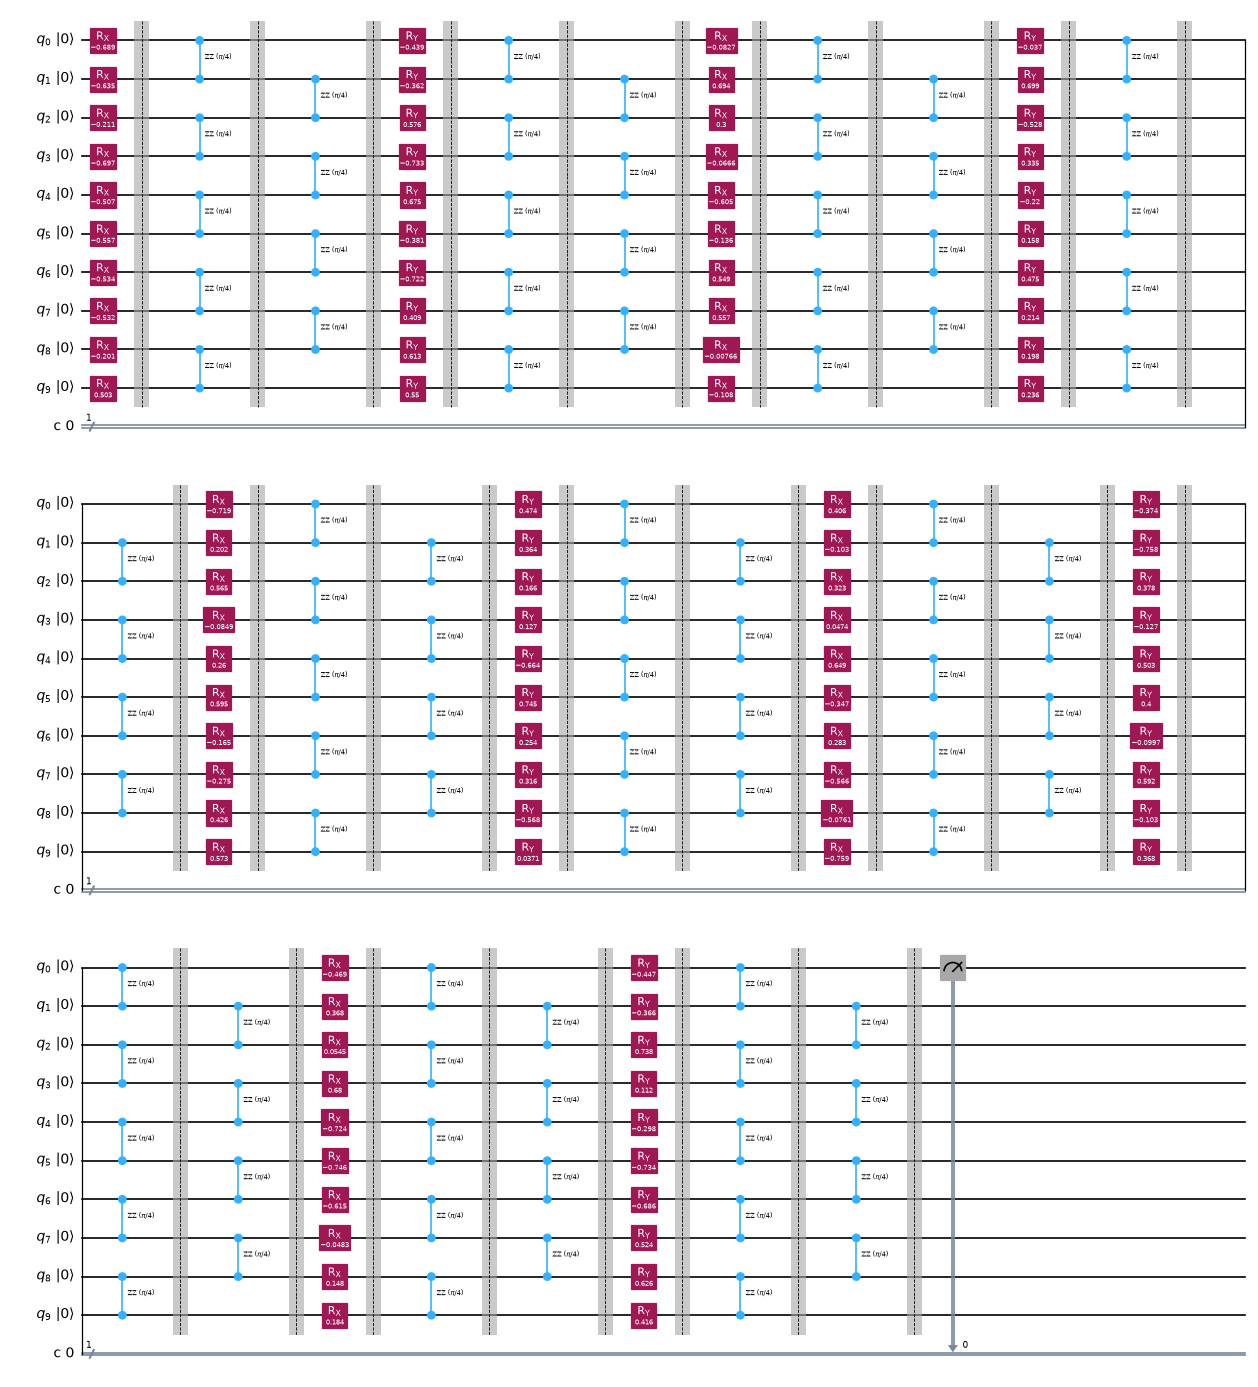

10 layer(s): mean <Z_0> = +0.112734 over 50 random circuits, 1024 shots each
15 layer(s): mean <Z_0> = +0.108477 over 50 random circuits, 1024 shots each
20 layer(s): mean <Z_0> = -0.017617 over 50 random circuits, 1024 shots each
25 layer(s): mean <Z_0> = -0.012266 over 50 random circuits, 1024 shots each
30 layer(s): mean <Z_0> = +0.063594 over 50 random circuits, 1024 shots each
35 layer(s): mean <Z_0> = +0.032227 over 50 random circuits, 1024 shots each
40 layer(s): mean <Z_0> = +0.017031 over 50 random circuits, 1024 shots each
45 layer(s): mean <Z_0> = -0.004141 over 50 random circuits, 1024 shots each
50 layer(s): mean <Z_0> = -0.010078 over 50 random circuits, 1024 shots each


In [3]:
if not layer_values or any(type(depth) is not int or depth < 1 for depth in layer_values):
    raise ValueError("layer_values must contain positive integers starting from 1")

#reset the stored results whenever the sweep is rerun
results = {0: 1.0} #the initial all-zero state has z expectation value 1
circuit_expectation_values = {} #all 50 measured z estimates at each depth
circuit_counts = {} #measurement counts for every random circuit
sample_circuits = {} #one circuit each for the 1-layer and 5-layer cases

for layers in layer_values:
    rng = np.random.default_rng(np.random.SeedSequence([seed, layers]))
    circuits = []

    for circuit_index in range(n_random_circuits):
        qc = QuantumCircuit(n_qubits, 1) #fresh all-zero state for each random circuit

        for layer_index in range(layers):
            #apply the rx stage and then the ry stage with fresh angles
            for rotate in (qc.rx, qc.ry):
                for q in range(n_qubits):
                    rotate(rng.uniform(-rotation_limit, rotation_limit), q)
                qc.barrier()

                #after each rotation stage, apply even pairs and then odd pairs
                for start in (0, 1):
                    for q in range(start, n_qubits - 1, 2):
                        qc.rzz(entangling_angle, q, q + 1)
                    qc.barrier()

        qc.measure(0, 0) #measure qubit 0 only after the final layer
        circuits.append(qc)

    #advance the shot rng across circuits instead of restarting the same samples
    sampler = StatevectorSampler(seed=np.random.default_rng(seed + layers))
    sampled_results = sampler.run(circuits, shots=shots).result()
    counts = [sample.data.c.get_counts() for sample in sampled_results]
    z_values = np.array([
        (c.get("0", 0) - c.get("1", 0)) / shots for c in counts
    ])
    circuit_counts[layers] = counts
    circuit_expectation_values[layers] = z_values
    results[layers] = float(np.mean(z_values))

    print(f"{layers} layer(s): mean <Z_0> = {results[layers]:+.6f} "
          f"over {n_random_circuits} random circuits, {shots} shots each")

    if layers in (1, 5):
        #display just the first of the 50 circuits at these two depths
        sample_circuits[layers] = circuits[0]
        fig = sample_circuits[layers].draw(output="mpl", fold=30, scale=0.6, initial_state=True)
        display(fig)
        plt.close(fig)


## plot the averaged values

Use the existing plotting function with the mean of 50 random circuits at each depth, plus the exact initial point (0 layers, 1). To change the depths, edit `layer_values` in setup, then rerun setup, the sweep, and this plotting cell.


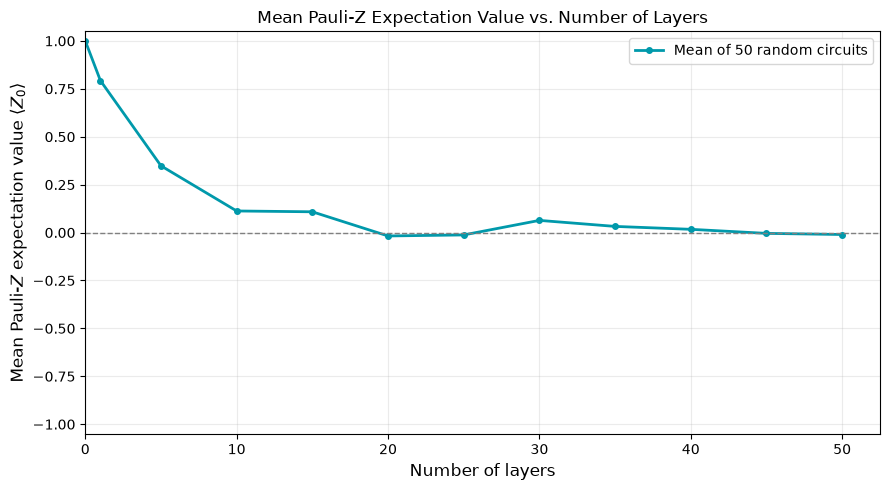

In [4]:
#plot the stored means together with the initial zero-layer value
circuit_depths = np.array(sorted(results))
expectation_values = np.array([results[depth] for depth in circuit_depths])
using_placeholder_data = False

plot_expectation_values(
    circuit_depths,
    expectation_values,
    placeholder=using_placeholder_data,
)
